<H1>OPT</H1> 
Looking at the SparkFun OPT4048 visible light sensor
<hr>
<H2>Modification history </H2><br> 
<table>
    <tr>
        <th> Modified </th>
        <th> By </th>
        <th> Reason </th>
    </tr>
    <tr> 
        <td> 29-Oct-26 </td>
        <td> CBL </td> 
        <td> Original </td>
    </tr>
</table>
<hr> 
<H2> References </H2> 
References: <br> 
<a href="https://pandas.pydata.org/docs/getting_started/index.html#getting-started"> PANDAS getting started</a> <br> 

N
<H2> Notes </H2>

In [1]:
# My imports
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

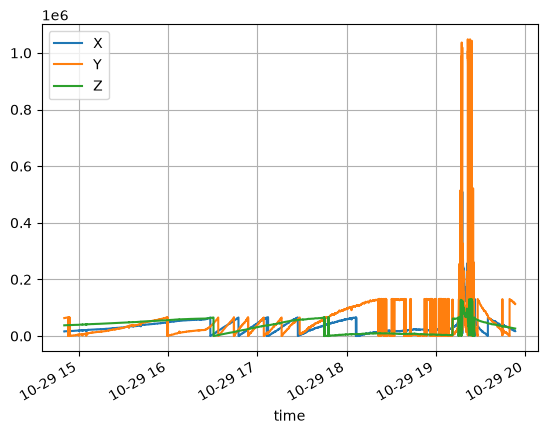

In [2]:
#
#
sunlight = pd.read_csv("261029_VIS.log",comment="#")
sunlight['time'] = pd.to_datetime(sunlight['Seconds'], unit='s')
sunlight.plot('time',y=['X','Y','Z'])
plt.grid()

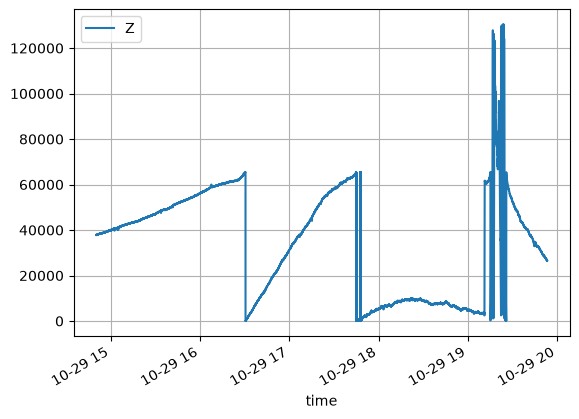

In [6]:
sunlight.plot('time','Z')
plt.grid()

What I'm concerned with in the plot above are the sawtooth like patterns. It is as if the change
from the packed bit data to full value is somehow being done incorrectly. In the
following dataset, I logged the Green(Y) mantissa (MY) and exponent(EY) into the csv logfile. 

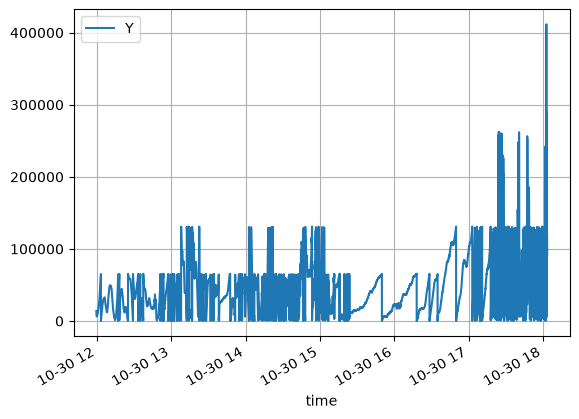

In [3]:
mexp = pd.read_csv("261030_VIS.log",comment="#")
mexp['time'] = pd.to_datetime(mexp['Seconds'], unit='s')
mexp.plot('time','Y')
plt.grid()

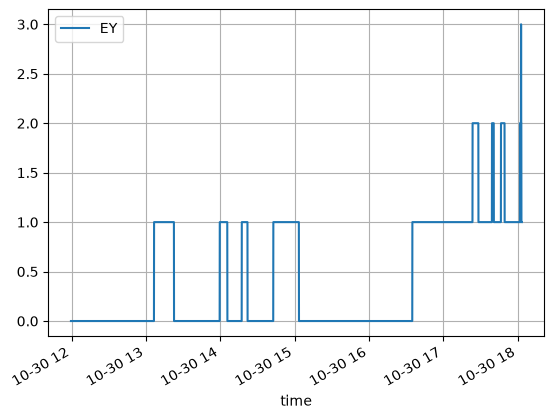

In [5]:
mexp.plot('time','EY')
plt.grid()

Ok, there is more going on here than meets the eye, Really seems like a packing issue. 
01-Nov-26<br> 
Think I fixed the packing issue. This dataset should have the fix installed. 

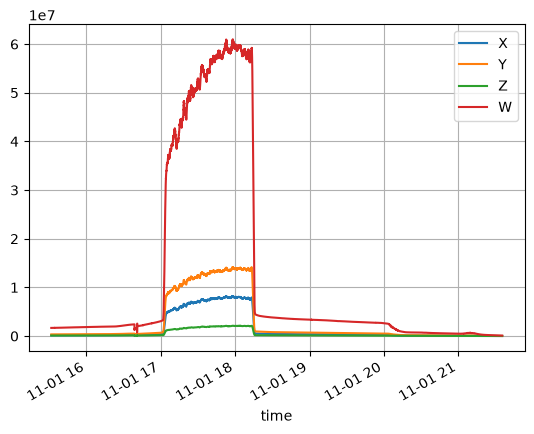

In [3]:
vis = pd.read_csv("261101_VIS.log",comment="#")
vis['time'] = pd.to_datetime(vis['Seconds'], unit='s')
vis.plot('time',y=['X','Y','Z','W'])
plt.grid()

The scaling looks correct. I'm just very surprised at the intensity of the light!
A typical lux value according to the web is 1.0e4 and this is 1.0e7, what causes this?

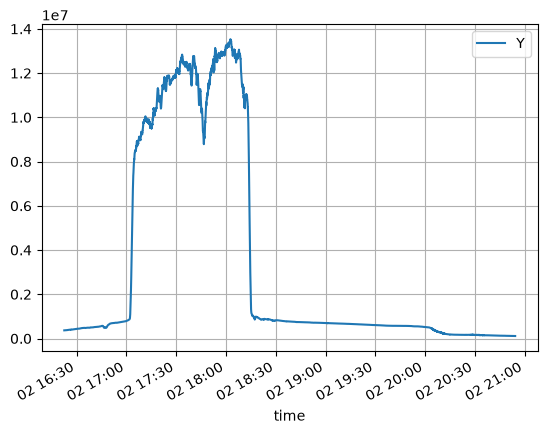

In [4]:
vis = pd.read_csv("261102_VIS.log",comment="#")
vis['time'] = pd.to_datetime(vis['Seconds'], unit='s')
vis.plot('time','Y')
plt.grid()

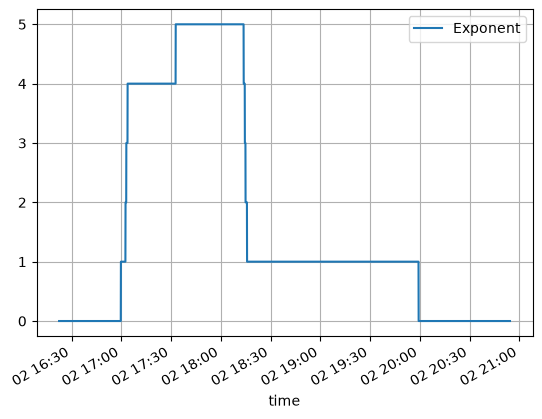

In [5]:
vis.plot('time','Exponent')
plt.grid()

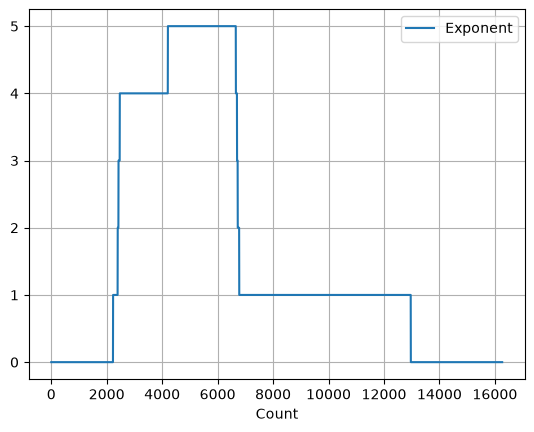

In [6]:
vis.plot('Count','Exponent')
plt.grid()

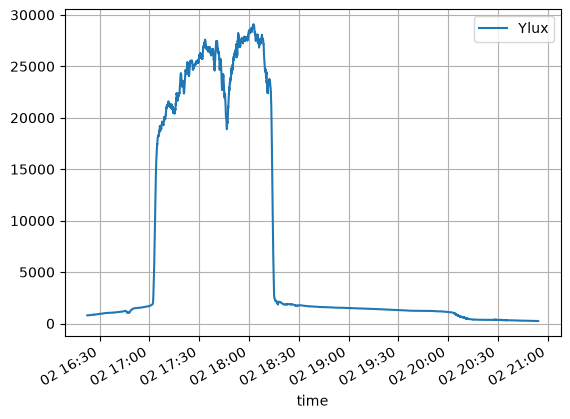

In [8]:
vis['Ylux'] = vis['Y']*2.15e-3
vis.plot('time','Ylux')
plt.grid()

And this is in the ballpark!! This does not calibrate the sensor. We can use it for relative measurements only. 
Lets see what sunset and nighttime looks like. 

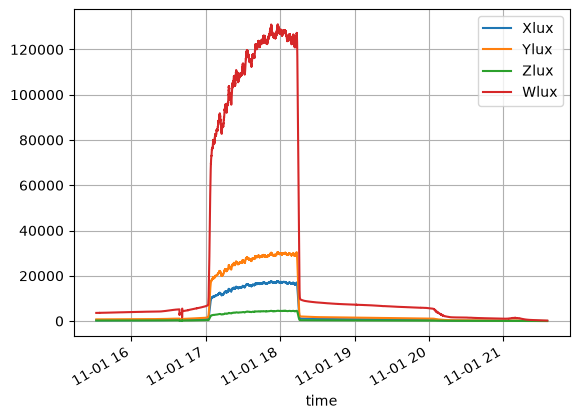

In [9]:
vis = pd.read_csv("261101_VIS.log",comment="#")
vis['time'] = pd.to_datetime(vis['Seconds'], unit='s')
vis['Xlux'] = vis['X']*2.15e-3
vis['Ylux'] = vis['Y']*2.15e-3
vis['Zlux'] = vis['Z']*2.15e-3
vis['Wlux'] = vis['W']*2.15e-3
vis.plot('time',y=['Xlux','Ylux','Zlux','Wlux'])
plt.grid()

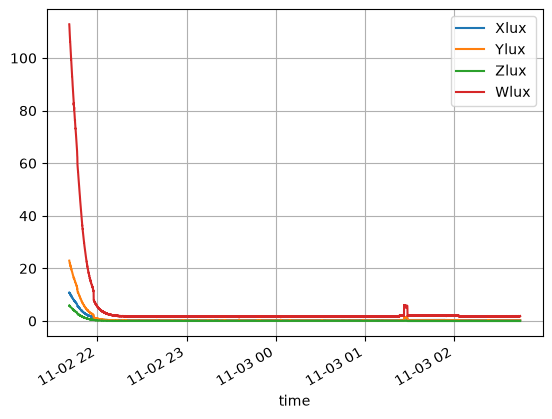

In [14]:
vis = pd.read_csv("261102_VIS_NIGHT.log",comment="#")
vis['time'] = pd.to_datetime(vis['Seconds'], unit='s')
vis['Xlux'] = vis['X']*2.15e-3
vis['Ylux'] = vis['Y']*2.15e-3
vis['Zlux'] = vis['Z']*2.15e-3
vis['Wlux'] = vis['W']*2.15e-3
vis.plot('time',y=['Xlux','Ylux','Zlux','Wlux'])
#vis.plot('time',y=['X','Y','Z','W'])
plt.grid()